# SmartTour CyL · Análisis exploratorio de datos

**Datasets turísticos de Castilla y León: primera exploración, calidad del dato y hallazgos principales**

| | |
|---|---|
| **Proyecto** | SmartTour-BigData |
| **Cuaderno** | `01_EDA_Datasets.ipynb` |
| **Fecha** | 03/11/2026 |
| **Entorno** | Python 3.12 · pandas · matplotlib (`.venv`, kernel *Python 3.12 (SmartTour .venv)*) |

**Objetivo.** Conocer la estructura, el contenido y la calidad de los cuatro datasets de partida antes de limpiarlos e integrarlos: tamaño, tipos de columna, estadísticas, valores nulos, duplicados y principales distribuciones.

**Cómo leer este cuaderno.** En cada paso aparece primero la salida de pandas y, debajo, una nota en un bloque de cita (como este) que explica qué significa esa salida *para ese dataset en concreto*.

## Índice

1. [Preparación](#setup)
2. [Fuentes de datos](#sources)
3. [Carga de los datasets](#load)
4. [Visión general](#overview)
5. [Municipios](#municipios)
6. [Registro de turismo](#hoteles)
7. [Monumentos](#monumentos)
8. [Oficinas de turismo](#oficinas)
9. [Conclusiones](#summary)

<a id="setup"></a>
## 1. Preparación

Librerías, opciones de visualización, un estilo de gráfico común para todo el cuaderno y cuatro utilidades:

| Utilidad | Para qué sirve |
|---|---|
| `fmt_es(n)` | Formatea números al estilo español (`2.248`, `47,1`) |
| `profile(df)` | Una fila por columna: tipo, nulos, % de nulos y valores distintos |
| `barh(counts, ...)` | Barras horizontales ordenadas con etiquetas de valor y porcentaje |
| `scatter_map(lon, lat, ...)` | Mapa rápido de puntos (longitud frente a latitud) |
| `CYL_PROVINCES` | Las 9 provincias de Castilla y León, para filtrar registros de fuera |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../datasets/smartTourData")


def fmt_es(n, dec=0):
    """Formatea un número al estilo español: punto de miles y coma decimal."""
    return f"{n:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")


pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda x: fmt_es(x, 2))

ACCENT = "#2a78d6"        # serie principal
ACCENT_LIGHT = "#86b6ef"  # serie secundaria / barras en tablas
NEUTRAL = "#c3c2b7"       # marcas sin énfasis
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e6e5e0"
SURFACE = "#fcfcfb"

CYL_PROVINCES = ["Ávila", "Burgos", "León", "Palencia", "Salamanca",
                 "Segovia", "Soria", "Valladolid", "Zamora"]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.formatter.use_locale": False,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "font.size": 10,
})


def profile(df: pd.DataFrame) -> pd.DataFrame:
    """Resumen por columna: tipo, valores no nulos, nulos, % de nulos y valores distintos."""
    return (
        pd.DataFrame({
            "tipo": df.dtypes.astype(str),
            "no_nulos": df.notna().sum(),
            "nulos": df.isna().sum(),
            "pct_nulos": df.isna().mean().mul(100),
            "distintos": df.nunique(),
        })
        .sort_values("pct_nulos", ascending=False)
    )


def style_profile(df: pd.DataFrame):
    """Tabla de perfil con una barra integrada en el porcentaje de nulos."""
    return (
        profile(df).style
        .bar(subset=["pct_nulos"], color=ACCENT_LIGHT, vmin=0, vmax=100)
        .format(precision=1, decimal=",", thousands=".")
        .format("{:.1f} %", subset=["pct_nulos"], decimal=",")
    )


def _titles(ax, title, subtitle):
    ax.set_title(title, pad=24 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_SECONDARY, fontsize=9.5)


def _axis_es(axis):
    axis.set_major_formatter(plt.FuncFormatter(
        lambda x, _: fmt_es(x) if float(x).is_integer() else fmt_es(x, 1)))


def barh(counts, title, subtitle=None, xlabel="Registros", colors=None,
         share=True, dec=0, suffix="", ax=None, sort=True):
    """Barras horizontales ordenadas (la mayor arriba) con su valor y su % sobre el total.
    sort=False mantiene el orden recibido (el primero abajo), para alinear varios paneles."""
    counts = counts.sort_values() if sort else counts
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(9, 0.34 * len(counts) + 1.6))
    bar_colors = colors.reindex(counts.index).tolist() if colors is not None else ACCENT
    ax.barh(counts.index.astype(str), counts.values, color=bar_colors, height=0.62)
    total = counts.sum()
    for y, v in enumerate(counts.values):
        label = fmt_es(v, dec) + suffix + (f"  ({fmt_es(v / total * 100)} %)" if share else "")
        ax.text(v, y, "  " + label, va="center", color=INK_SECONDARY, fontsize=9)
    ax.set_xlim(0, counts.max() * 1.22)
    _titles(ax, title, subtitle)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    _axis_es(ax.xaxis)
    if own_fig:
        plt.tight_layout()
        plt.show()


def scatter_map(lon, lat, title, subtitle=None, sizes=6, ax=None):
    """Dispersión longitud/latitud con una proporción aproximadamente correcta para 41,5° N."""
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(8, 6.5))
    ax.scatter(lon, lat, s=sizes, color=ACCENT, alpha=0.45, linewidths=0)
    ax.set_aspect(1 / np.cos(np.radians(41.5)))
    _titles(ax, title, subtitle)
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    _axis_es(ax.xaxis)
    _axis_es(ax.yaxis)
    if own_fig:
        plt.tight_layout()
        plt.show()

<a id="sources"></a>
## 2. Fuentes de datos

| Dataset | Archivo | Codificación | Contenido |
|---|---|---|---|
| `municipios` | `municipios/MunicipiosJCyL.csv` | Latin-1, decimal `,` | Municipios de Castilla y León con población, códigos y coordenadas |
| `hoteles` | `hoteles/registro-de-turismo-de-castilla-y-leon.csv` | UTF-8 | Registro de turismo regional: alojamientos, restaurantes, bares, agencias… |
| `monumentos` | `monumentos/relacion-monumentos.csv` | UTF-8 | Monumentos con tipo, periodo histórico, descripción y coordenadas |
| `oficinas` | `oficinas_turnismo/oficinas_turismo_castilla_y_leon.csv` | UTF-8 | Oficinas de información turística |

Todos los archivos usan `;` como separador. Las columnas de códigos, código postal y teléfono se leen como texto para conservar los ceros iniciales (`05001` no debe convertirse en `5001`).

> Origen: datos abiertos publicados por la Junta de Castilla y León (pendiente de confirmar y de enlazar con la URL exacta y la fecha de descarga).

<a id="load"></a>
## 3. Carga de los datasets

In [2]:
municipios = pd.read_csv(
    DATA_DIR / "municipios" / "MunicipiosJCyL.csv",
    sep=";",
    encoding="latin-1",
    decimal=",",
    dtype={"Cod_Municipio": str, "Cod_Provincia": str, "Cod_INE": str},
)

hoteles = pd.read_csv(
    DATA_DIR / "hoteles" / "registro-de-turismo-de-castilla-y-leon.csv",
    sep=";",
    encoding="utf-8",
    dtype={"C.Postal": str, "Teléfono 1": str, "Teléfono 2": str, "Teléfono 3": str},
    low_memory=False,
)

monumentos = pd.read_csv(
    DATA_DIR / "monumentos" / "relacion-monumentos.csv",
    sep=";",
    encoding="utf-8",
    dtype={"codigoPostal": str},
)

oficinas = pd.read_csv(
    DATA_DIR / "oficinas_turnismo" / "oficinas_turismo_castilla_y_leon.csv",
    sep=";",
    encoding="utf-8",
)

datasets = {
    "municipios": municipios,
    "hoteles": hoteles,
    "monumentos": monumentos,
    "oficinas": oficinas,
}

# Detener el cuaderno si un archivo cambia de forma o pierde una columna clave
for name, df in datasets.items():
    assert len(df) > 0, f"{name} está vacío"
assert {"Municipio", "Provincia", "Población"} <= set(municipios.columns)
assert {"Establecimiento", "Provincia", "Municipio"} <= set(hoteles.columns)
assert {"nombre", "tipoMonumento", "poblacion_provincia"} <= set(monumentos.columns)
assert {"Provincia", "Localidad"} <= set(oficinas.columns)
print("Todos los datasets se han cargado y validado.")

Todos los datasets se han cargado y validado.


<a id="overview"></a>
## 4. Visión general

Tamaño, completitud y duplicados de cada dataset, uno junto a otro.

In [3]:
overview = pd.DataFrame([
    {
        "dataset": name,
        "filas": df.shape[0],
        "columnas": df.shape[1],
        "pct_celdas_nulas": df.isna().sum().sum() / df.size * 100,
        "filas_duplicadas": int(df.duplicated().sum()),
        "memoria_mb": df.memory_usage(deep=True).sum() / 1e6,
    }
    for name, df in datasets.items()
]).set_index("dataset")

(
    overview.style
    .bar(subset=["pct_celdas_nulas"], color=ACCENT_LIGHT, vmin=0, vmax=100)
    .format(precision=1, decimal=",", thousands=".")
    .format("{:.1f} %", subset=["pct_celdas_nulas"], decimal=",")
    .format("{:.1f} MB", subset=["memoria_mb"], decimal=",")
)

,filas,columnas,pct_celdas_nulas,filas_duplicadas,memoria_mb
dataset,,,,,
municipios,2.248,13,"14,5 %",0,"1,1 MB"
hoteles,35.930,27,"47,1 %",0,"42,4 MB"
monumentos,1.378,18,"5,3 %",0,"2,3 MB"
oficinas,263,6,"1,6 %",0,"0,1 MB"


> El registro de turismo (`hoteles`) domina: **35.930 filas y 42 MB**, más del 90 % de la memoria de los cuatro datasets juntos, y también el mayor porcentaje de celdas vacías (47 %). Los otros tres son tablas de referencia pequeñas que caben sin problema en memoria. Ninguno tiene filas completamente duplicadas.

<a id="municipios"></a>
## 5. Municipios

Tabla de referencia del territorio: una fila por municipio de Castilla y León con códigos INE, población, agrupaciones administrativas y coordenadas. Es la **columna vertebral para unir los demás datasets**.

### Número de filas y columnas

In [4]:
municipios.shape

(2248, 13)

> **2.248 filas × 13 columnas**: una fila por municipio. Castilla y León es la comunidad autónoma con más municipios de España y aquí están todos. Las 13 columnas cubren la identificación (nombre y códigos), las agrupaciones administrativas, la población y dos sistemas de coordenadas.

### Tipos de columnas

In [5]:
municipios.info()

<class 'pandas.DataFrame'>
RangeIndex: 2248 entries, 0 to 2247
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Municipio                  2248 non-null   str    
 1   Cod_Municipio              2248 non-null   str    
 2   Provincia                  2248 non-null   str    
 3   Cod_Provincia              2248 non-null   str    
 4   Cod_INE                    2248 non-null   str    
 5   Población                  2248 non-null   int64  
 6   Mancomunidades             2037 non-null   str    
 7   Entidades_Locales_Menores  441 non-null    str    
 8   Comarca                    38 non-null     str    
 9   Longitud                   2248 non-null   float64
 10  Latitud                    2248 non-null   float64
 11  CoordenadaX                2248 non-null   float64
 12  CoordenadaY                2248 non-null   float64
dtypes: float64(4), int64(1), str(8)
memory usage: 228.4 KB


> 8 columnas de texto, 4 decimales y 1 entera; solo 1,1 MB. Los códigos (`Cod_Municipio`, `Cod_Provincia`, `Cod_INE`) son texto a propósito, para conservar el cero inicial. `Población` y las cuatro coordenadas están completas y son numéricas porque el archivo se leyó con `decimal=","`. Solo `Mancomunidades`, `Entidades_Locales_Menores` y `Comarca` tienen huecos.

### Primeros registros

In [6]:
municipios.head()

,Municipio,Cod_Municipio,Provincia,Cod_Provincia,Cod_INE,Población,Mancomunidades,Entidades_Locales_Menores,Comarca,Longitud,Latitud,CoordenadaX,CoordenadaY
0,ADANERO,001,ÁVILA,05,05001,207,"COMARCA DE LA MORAÑA,RIBERA DEL ADAJA",NaN,NaN,"-4,60","40,94","365.003,90","4.533.805,03"
1,ALBORNOS,005,ÁVILA,05,05005,170,"COMARCA DE LA MORAÑA,TIERRAS DE MORAÑA",NaN,NaN,"-4,89","40,84","340.963,64","4.522.203,14"
2,ALDEANUEVA DE SANTA CRUZ,007,ÁVILA,05,05007,100,BARCO Y PIEDRAHÍTA,NaN,NaN,"-5,42","40,38","294.609,69","4.472.963,05"
3,ALDEASECA,008,ÁVILA,05,05008,211,"AGUA LOS ARENALES,COMARCA DE LA MORAÑA,TIERRAS DE MORAÑA",NaN,NaN,"-4,82","41,05","347.253,98","4.545.810,20"
4,AMAVIDA,012,ÁVILA,05,05012,131,VALLE DE AMBLÉS,NaN,NaN,"-5,06","40,57","325.523,49","4.493.230,98"


> Los nombres y las provincias están en **MAYÚSCULAS con tilde** (`ADANERO`, `ÁVILA`), a diferencia de los otros datasets. `Mancomunidades` agrupa varias asociaciones en una misma celda separadas por comas (`COMARCA DE LA MORAÑA,RIBERA DEL ADAJA`). Cada municipio tiene dos pares de coordenadas: `Longitud`/`Latitud` en grados y `CoordenadaX`/`CoordenadaY` en metros (UTM proyectadas).

### Estadísticas

In [7]:
municipios.describe()

,Población,Longitud,Latitud,CoordenadaX,CoordenadaY
count,"2.248,00","2.248,00","2.248,00","2.248,00","2.248,00"
mean,"1.066,95","-4,74","41,61","354.537,12","4.608.090,54"
std,"9.137,33","1,14","0,70","95.053,63","77.652,68"
min,"6,00","-7,00","40,15","169.256,17","4.447.085,24"
25%,"75,00","-5,63","41,03","279.733,32","4.545.346,81"
50%,"162,00","-4,85","41,64","345.307,64","4.610.619,38"
75%,"394,25","-3,93","42,16","423.400,16","4.669.017,97"
max,"302.614,00","-1,81","43,15","598.867,62","4.779.374,63"


> `Población` tiene una **media de 1.067 pero una mediana de 162** y una desviación típica de 9.137: unas pocas ciudades disparan la media. Va de 6 habitantes (Villanueva de Gormaz, Soria) a 302.614 (Valladolid). La longitud (−7,00 a −1,81) y la latitud (40,15 a 43,15) caen siempre dentro de la región: no hay errores de coordenadas. Las estadísticas de `CoordenadaX`/`CoordenadaY` no significan nada por sí solas: son posiciones, no cantidades.

### Valores nulos

In [8]:
municipios.isnull().sum()

Municipio                       0
Cod_Municipio                   0
Provincia                       0
Cod_Provincia                   0
Cod_INE                         0
Población                       0
Mancomunidades                211
Entidades_Locales_Menores    1807
Comarca                      2210
Longitud                        0
Latitud                         0
CoordenadaX                     0
CoordenadaY                     0
dtype: int64

La misma información como perfil, ordenada por porcentaje de nulos:

In [9]:
style_profile(municipios)

,tipo,no_nulos,nulos,pct_nulos,distintos
Comarca,str,38,2.210,"98,3 %",1
Entidades_Locales_Menores,str,441,1.807,"80,4 %",439
Mancomunidades,str,2.037,211,"9,4 %",363
Cod_Municipio,str,2.248,0,"0,0 %",465
Municipio,str,2.248,0,"0,0 %",2.248
Cod_INE,str,2.248,0,"0,0 %",2.248
Cod_Provincia,str,2.248,0,"0,0 %",9
Provincia,str,2.248,0,"0,0 %",9
Población,int64,2.248,0,"0,0 %",815
Longitud,float64,2.248,0,"0,0 %",2.247


> Aquí los nulos son sobre todo **estructurales, no datos perdidos**:
> - `Comarca` (2.210 nulos, 98 %): solo tienen valor los 38 municipios de *El Bierzo*, la única comarca constituida legalmente en la región.
> - `Entidades_Locales_Menores` (1.807, 80 %): un nulo significa que el municipio no tiene entidades locales menores.
> - `Mancomunidades` (211, 9 %): municipios que no pertenecen a ninguna mancomunidad.

### Valores duplicados

In [10]:
municipios.duplicated().sum()

np.int64(0)

In [11]:
municipios["Cod_INE"].is_unique

True

> No hay filas duplicadas y `Cod_INE` es único (`True`), así que puede usarse como **clave primaria** del territorio.

### Nombre de las columnas

In [12]:
municipios.columns

Index(['Municipio', 'Cod_Municipio', 'Provincia', 'Cod_Provincia', 'Cod_INE',
       'Población', 'Mancomunidades', 'Entidades_Locales_Menores', 'Comarca',
       'Longitud', 'Latitud', 'CoordenadaX', 'CoordenadaY'],
      dtype='str')

> Los nombres mezclan convenciones (`Cod_INE`, `Entidades_Locales_Menores`) e incluyen una tilde (`Población`). Antes de integrar, conviene renombrarlos a minúsculas sin tildes con guiones bajos (`poblacion`, `cod_ine`).

### Distribuciones

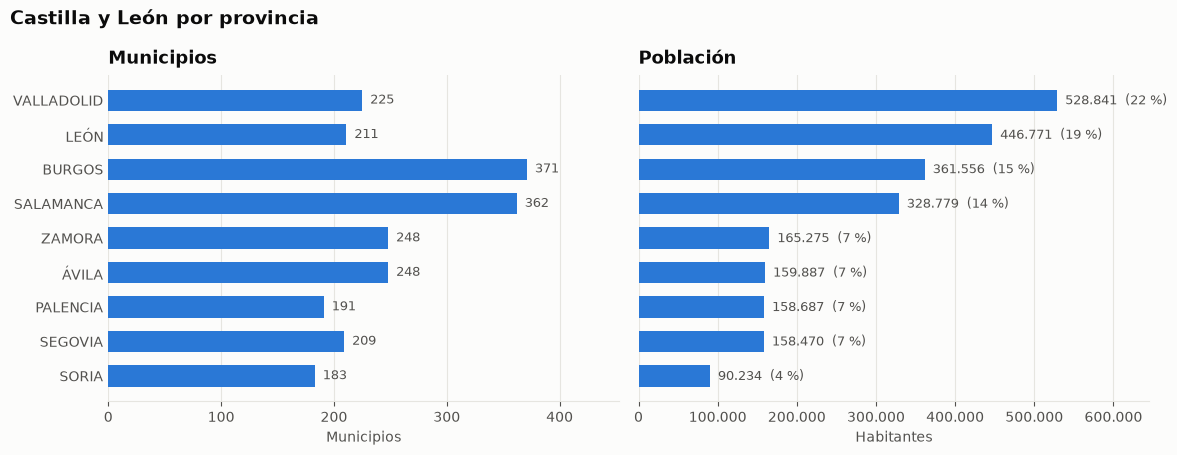

In [13]:
by_province = (
    municipios.groupby("Provincia")
    .agg(municipios=("Municipio", "size"), poblacion=("Población", "sum"))
    .sort_values("poblacion")
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
# sort=False: los dos paneles mantienen el orden por población para que las filas coincidan
barh(by_province["municipios"], "Municipios", share=False, xlabel="Municipios", ax=axes[0], sort=False)
barh(by_province["poblacion"], "Población", share=True, xlabel="Habitantes", ax=axes[1], sort=False)
fig.suptitle("Castilla y León por provincia", x=0.01, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

> Los dos paneles mantienen el mismo orden de provincias (por población) para poder compararlos fila a fila. **Burgos tiene más municipios (371), pero Valladolid más habitantes (528.841, el 22 %)**. Soria es el caso extremo de dispersión: 183 municipios para solo 90.234 personas.

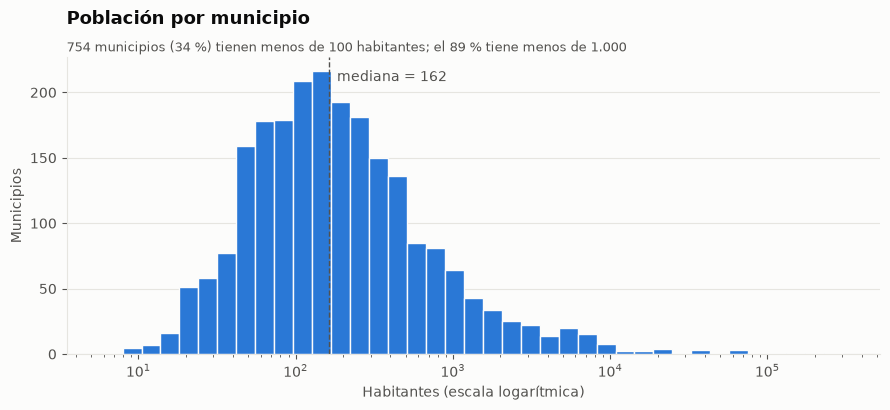

In [14]:
pop = municipios["Población"]
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.logspace(np.log10(pop.min()), np.log10(pop.max()), 40)
ax.hist(pop, bins=bins, color=ACCENT, edgecolor=SURFACE, linewidth=1)
ax.set_xscale("log")
_titles(ax, "Población por municipio",
        f"{fmt_es((pop < 100).sum())} municipios ({fmt_es((pop < 100).mean() * 100)} %) tienen menos de 100 habitantes; "
        f"el {fmt_es((pop < 1000).mean() * 100)} % tiene menos de 1.000")
ax.set_xlabel("Habitantes (escala logarítmica)")
ax.set_ylabel("Municipios")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.axvline(pop.median(), color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.annotate(f"mediana = {fmt_es(pop.median())}", xy=(pop.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK_SECONDARY)
plt.tight_layout()
plt.show()

> El eje logarítmico es necesario porque la población abarca cinco órdenes de magnitud. **El 89 % de los municipios tiene menos de 1.000 habitantes**: un indicador turístico por municipio estará dominado por pueblos muy pequeños, así que es mejor agregar por provincia o ponderar por población.

In [15]:
municipios.nlargest(5, "Población")[["Municipio", "Provincia", "Población"]]

,Municipio,Provincia,Población
1954,VALLADOLID,VALLADOLID,302614
292,BURGOS,BURGOS,177402
1286,SALAMANCA,SALAMANCA,146110
702,LEÓN,LEÓN,123446
926,PALENCIA,PALENCIA,77466


> Los cinco municipios más poblados son las capitales de Valladolid, Burgos, Salamanca, León y Palencia.

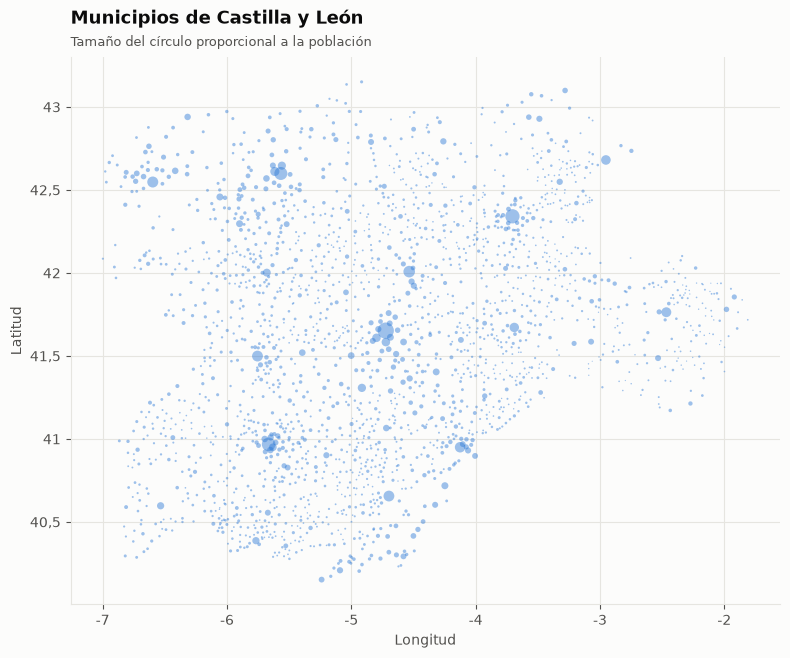

In [16]:
scatter_map(municipios["Longitud"], municipios["Latitud"],
            "Municipios de Castilla y León", "Tamaño del círculo proporcional a la población",
            sizes=np.sqrt(municipios["Población"]) / 4)

> La nube de puntos dibuja el contorno de la región, lo que confirma que las coordenadas son correctas. Los municipios se reparten de forma uniforme por el territorio, pero casi todos los círculos son diminutos: la población se concentra en los pocos círculos grandes de las capitales de provincia.

### Hallazgos principales


- **2.248 municipios con `Cod_INE` único**: esta tabla es la clave para unir todo lo demás.
- **La población está muy concentrada** (mediana 162, máximo 302.614): hay que usar medianas, agregados provinciales o escalas logarítmicas.
- Los nulos de `Comarca`, `Entidades_Locales_Menores` y `Mancomunidades` significan *"no aplica"*, no son datos perdidos.
- Las coordenadas están completas y son válidas.
- Los nombres están en mayúsculas (`EL BARRACO`) mientras otros datasets usan otras formas (`Barraco (El)`): los cruces necesitan normalizar el texto.

<a id="hoteles"></a>
## 6. Registro de turismo

Aunque el archivo se llame así, no contiene solo hoteles: es el **registro de turismo regional completo**, con alojamientos, pero también bares, restaurantes, cafeterías, agencias de viajes y empresas de turismo activo. Es el dataset más grande y el menos limpio.

### Número de filas y columnas

In [17]:
hoteles.shape

(35930, 27)

> **35.930 filas × 27 columnas**: una fila por establecimiento turístico registrado. Es 16 veces más grande que la tabla de municipios, así que concentra la mayor parte del análisis y del trabajo de limpieza.

### Tipos de columnas

In [18]:
hoteles.info()

<class 'pandas.DataFrame'>
RangeIndex: 35930 entries, 0 to 35929
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Establecimiento                        35930 non-null  str    
 1   N.Registro                             35567 non-null  str    
 2   Codigo                                 363 non-null    str    
 3   Tipo                                   35927 non-null  str    
 4   Categoría                              29233 non-null  str    
 5   Especialidades                         261 non-null    str    
 6   Clase                                  360 non-null    str    
 7   Nombre                                 35925 non-null  str    
 8   Dirección                              35750 non-null  str    
 9   C.Postal                               35785 non-null  str    
 10  Provincia                              35925 non-null  str    
 11  Municipio    

> 23 columnas de texto y 4 decimales; **42,4 MB en memoria**. `Plazas`, `GPS.Longitud` y `GPS.Latitud` son numéricas. `Column 27` también aparece como decimal, pero solo porque está completamente vacía. Los teléfonos y códigos postales se han forzado a texto.

### Primeros registros

In [19]:
hoteles.head()

,Establecimiento,N.Registro,Codigo,Tipo,Categoría,Especialidades,Clase,Nombre,Dirección,C.Postal,Provincia,Municipio,Localidad,Nucleo,Teléfono 1,Teléfono 2,Teléfono 3,Email,web,Q Calidad,Posada Real,Plazas,GPS.Longitud,GPS.Latitud,accesible a personas con discapacidad,Column 27,Posición
0,Turismo Activo,47/000047,NaN,Profesional de Turismo Activo,NaN,NaN,NaN,BERNARDO MORO MENENDEZ,Calle Rio Somiedo 1 2º C,33840,Asturias,Somiedo,POLA DE SOMIEDO,POLA DE SOMIEDO,616367277,NaN,NaN,bernardomoro@hotmail.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Vivienda turística,05/000802,NaN,Piso,NaN,NaN,NaN,LAS GEMELAS DE ARÉVALO,Calle DE LA CORRALIZA 2 PB 16,05200,Ávila,Arévalo,AREVALO,AREVALO,676812242,920700759,NaN,vut.lasgemelasdearevalo@gmail.com,NaN,NaN,NaN,"4,00",NaN,NaN,Si,NaN,NaN
2,Vivienda turística,05/000803,NaN,Casa,NaN,NaN,NaN,EL CHAPARRAL,Paraje EL HORCO POÍGONO 23 PARCELA 110 110,05480,Ávila,Candeleda,CANDELEDA,CANDELEDA,695159653,NaN,NaN,alfonsogap@gmail.com,NaN,NaN,NaN,"6,00",NaN,NaN,NaN,NaN,NaN
3,Vivienda turística,05/000806,NaN,Chalé,NaN,NaN,NaN,CASA DEL PINTOR ANTONIO MESA,Calle SAN PEDRO BAUTISTA 4,05410,Ávila,Mombeltrán,MOMBELTRAN,MOMBELTRAN,639125993,639468867,NaN,casadelpintor@antoniomesa.es,NaN,NaN,NaN,"10,00",NaN,NaN,NaN,NaN,NaN
4,Vivienda turística,05/000809,NaN,Casa,NaN,NaN,NaN,GORDOLOBO DEL HORCO - EL BOSQUE DE CANDELEDA,Carretera CANDELEDA A MADRIGAL-PARAJE DEL HORCO- GORDOLO...,05480,Ávila,Candeleda,CANDELEDA,CANDELEDA,620382268,NaN,NaN,elisabet@garbanmadrid.com,NaN,NaN,NaN,"15,00",NaN,NaN,NaN,NaN,NaN


> El primer registro es un profesional de turismo activo de **Somiedo (Asturias)**: el registro incluye empresas inscritas en Castilla y León pero situadas fuera. `Categoría` usa una escala distinta según el tipo (estrellas en hoteles, tenedores en restaurantes, tazas en cafeterías), así que no se puede comparar entre tipos. La mayoría de columnas opcionales ya están vacías en estas cinco filas.

### Estadísticas

In [20]:
hoteles.describe()

,Plazas,GPS.Longitud,GPS.Latitud,Column 27
count,"27.040,00","7.451,00","7.448,00","0,00"
mean,"43,27","-4,66","41,46",NaN
std,"70,52","1,37","2,72",NaN
min,"0,00","-42,00","-5,00",NaN
25%,"8,00","-5,59","40,92",NaN
50%,"25,00","-4,69","41,65",NaN
75%,"53,00","-3,70","42,34",NaN
max,"2.050,00","5,62","53,81",NaN


> - **`Plazas` no significa lo mismo en todos los tipos**: son camas en los alojamientos y asientos en restaurantes y bares. El máximo (2.050) es un restaurante (*El Mirador*, Villamayor), no un hotel. Solo debe sumarse dentro de los tipos de alojamiento.
> - **Las columnas GPS contienen valores imposibles**: la latitud va de −5 a 53,81 y la longitud de −42 a 5,62, cuando la región está aproximadamente entre 40 y 43,5° N y entre 7,2 y 1,7° O. Valores como 0,008 apuntan a una conversión de coordenadas mal hecha.

### Valores nulos

In [21]:
hoteles.isnull().sum()

Establecimiento                              0
N.Registro                                 363
Codigo                                   35567
Tipo                                         3
Categoría                                 6697
Especialidades                           35669
Clase                                    35570
Nombre                                       5
Dirección                                  180
C.Postal                                   145
Provincia                                    5
Municipio                                  132
Localidad                                  133
Nucleo                                    2505
Teléfono 1                                1167
Teléfono 2                               27585
Teléfono 3                               35558
Email                                    17347
web                                      30123
Q Calidad                                35913
Posada Real                              35899
Plazas       

La misma información como perfil, ordenada por porcentaje de nulos:

In [22]:
style_profile(hoteles)

,tipo,no_nulos,nulos,pct_nulos,distintos
Column 27,float64,0,35.930,"100,0 %",0
Q Calidad,str,17,35.913,"100,0 %",1
Posada Real,str,31,35.899,"99,9 %",1
Especialidades,str,261,35.669,"99,3 %",23
Clase,str,360,35.570,"99,0 %",3
Codigo,str,363,35.567,"99,0 %",363
Teléfono 3,str,372,35.558,"99,0 %",359
web,str,5.807,30.123,"83,8 %",4.640
GPS.Latitud,float64,7.448,28.482,"79,3 %",6.675
Posición,str,7.448,28.482,"79,3 %",6.867


> - `Column 27` (100 %) es un resto de la exportación.
> - `Especialidades`, `Codigo`, `Clase` y `Teléfono 3` están vacías en torno al 99 %; `web`, el 84 %; GPS, el 79 %.
> - **`Q Calidad` y `Posada Real` parecen vacías, pero son indicadores de sí/no**: solo contienen `Si` (17 y 31 establecimientos), así que un nulo significa *no*. Lo mismo ocurre con `accesible a personas con discapacidad` (10.008 `Si`). Hay que convertirlas a booleanos en lugar de eliminarlas.

### Valores duplicados

In [23]:
hoteles.duplicated().sum()

np.int64(0)

In [24]:
hoteles.duplicated(["Nombre", "Municipio", "Establecimiento"]).sum()

np.int64(312)

> Ninguna fila está duplicada en sus 27 columnas, pero **312 registros comparten nombre, municipio y tipo de establecimiento** (segunda comprobación). Son posibles duplicados o varias unidades del mismo negocio; hay que revisarlos antes de contar establecimientos.

### Nombre de las columnas

In [25]:
hoteles.columns

Index(['Establecimiento', 'N.Registro', 'Codigo', 'Tipo', 'Categoría',
       'Especialidades', 'Clase', 'Nombre', 'Dirección', 'C.Postal',
       'Provincia', 'Municipio', 'Localidad', 'Nucleo', 'Teléfono 1',
       'Teléfono 2', 'Teléfono 3', 'Email', 'web', 'Q Calidad', 'Posada Real',
       'Plazas', 'GPS.Longitud', 'GPS.Latitud',
       'accesible a personas con discapacidad', 'Column 27', 'Posición'],
      dtype='str')

> Es el dataset con los nombres menos coherentes: espacios (`Teléfono 1`), puntos (`C.Postal`, `GPS.Latitud`), tildes, una frase entera como nombre (`accesible a personas con discapacidad`) y un genérico `Column 27`. Hay que renombrarlos todos antes de trabajar con los datos.

### Distribuciones

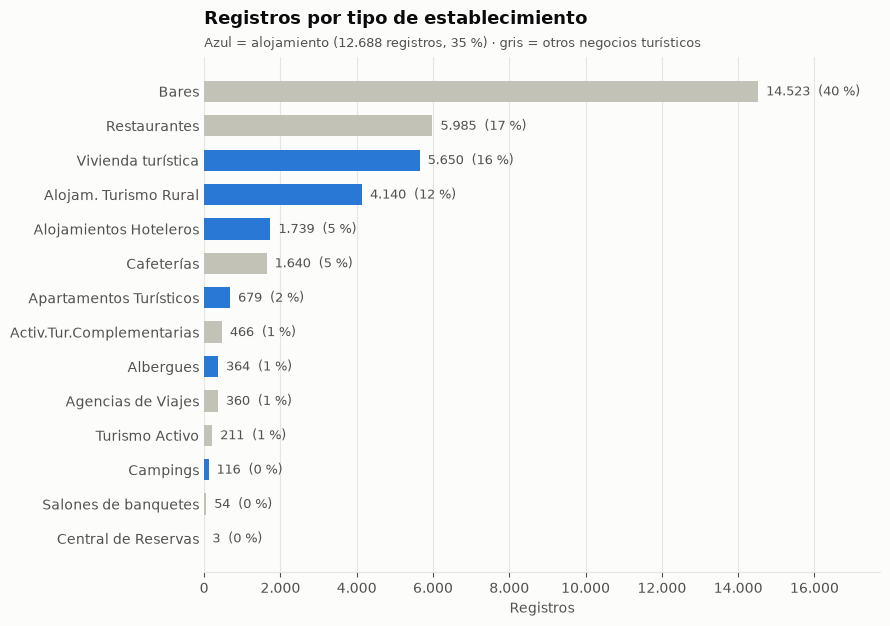

In [26]:
ACCOMMODATION = ["Alojamientos Hoteleros", "Alojam. Turismo Rural", "Vivienda turística",
                 "Apartamentos Turísticos", "Albergues", "Campings"]
types = hoteles["Establecimiento"].value_counts()
type_colors = pd.Series(np.where(types.index.isin(ACCOMMODATION), ACCENT, NEUTRAL), index=types.index)
n_acc = types[types.index.isin(ACCOMMODATION)].sum()
barh(types, "Registros por tipo de establecimiento",
     f"Azul = alojamiento ({fmt_es(n_acc)} registros, {fmt_es(n_acc / types.sum() * 100)} %) · "
     "gris = otros negocios turísticos",
     colors=type_colors)

> **Los bares son el 40 % del registro** (14.523) y los restaurantes otro 17 %. El alojamiento, que es el núcleo de un análisis turístico, supone el 35 % de los registros, encabezado por las viviendas turísticas (5.650) y el turismo rural (4.140).

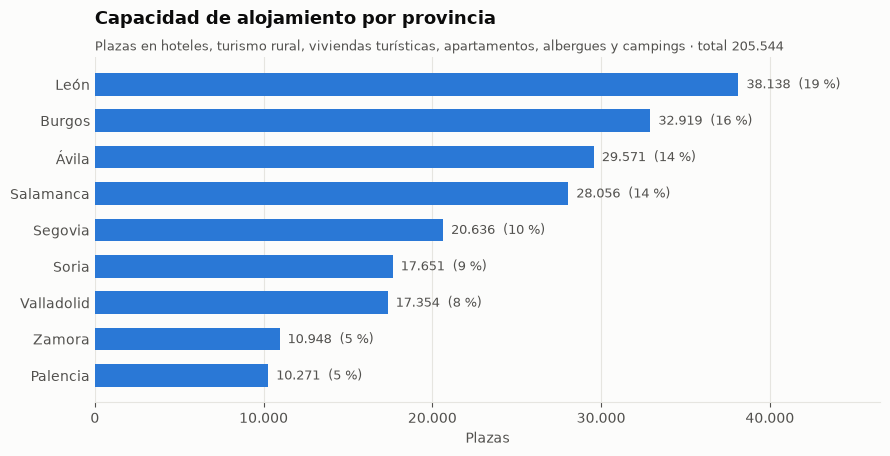

In [27]:
accommodation = hoteles[hoteles["Establecimiento"].isin(ACCOMMODATION)
                        & hoteles["Provincia"].isin(CYL_PROVINCES)]
barh(accommodation.groupby("Provincia")["Plazas"].sum(),
     "Capacidad de alojamiento por provincia",
     "Plazas en hoteles, turismo rural, viviendas turísticas, apartamentos, albergues y campings · "
     f"total {fmt_es(accommodation['Plazas'].sum())}",
     xlabel="Plazas")

> Solo se suman los tipos de alojamiento, porque únicamente ahí `Plazas` son camas. **León (38.138 plazas) y Burgos (32.919) concentran la mayor capacidad**, mientras que Palencia y Zamora tienen la menor. Es el primer indicador real de oferta para SmartTour.

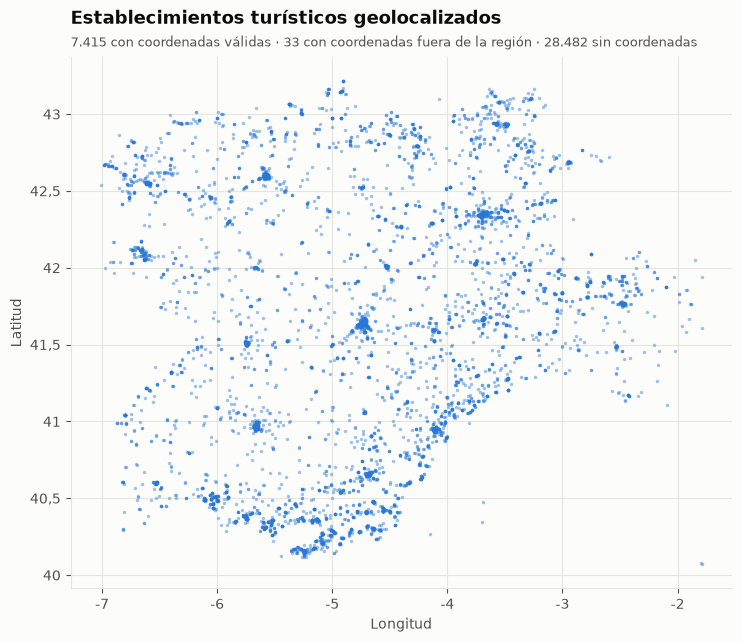

In [28]:
lat, lon = hoteles["GPS.Latitud"], hoteles["GPS.Longitud"]
valid = lat.between(40, 43.5) & lon.between(-7.2, -1.7)
scatter_map(lon[valid], lat[valid], "Establecimientos turísticos geolocalizados",
            f"{fmt_es(valid.sum())} con coordenadas válidas · {fmt_es((lat.notna() & ~valid).sum())} con "
            f"coordenadas fuera de la región · {fmt_es(lat.isna().sum())} sin coordenadas")

> Solo uno de cada cinco establecimientos se puede situar en el mapa. Los que sí, se concentran en las capitales y en las zonas de sierra de Ávila y Segovia (Gredos y Guadarrama). Los pocos puntos fuera de la región se excluyen aquí y habrá que corregirlos o descartarlos en la limpieza.

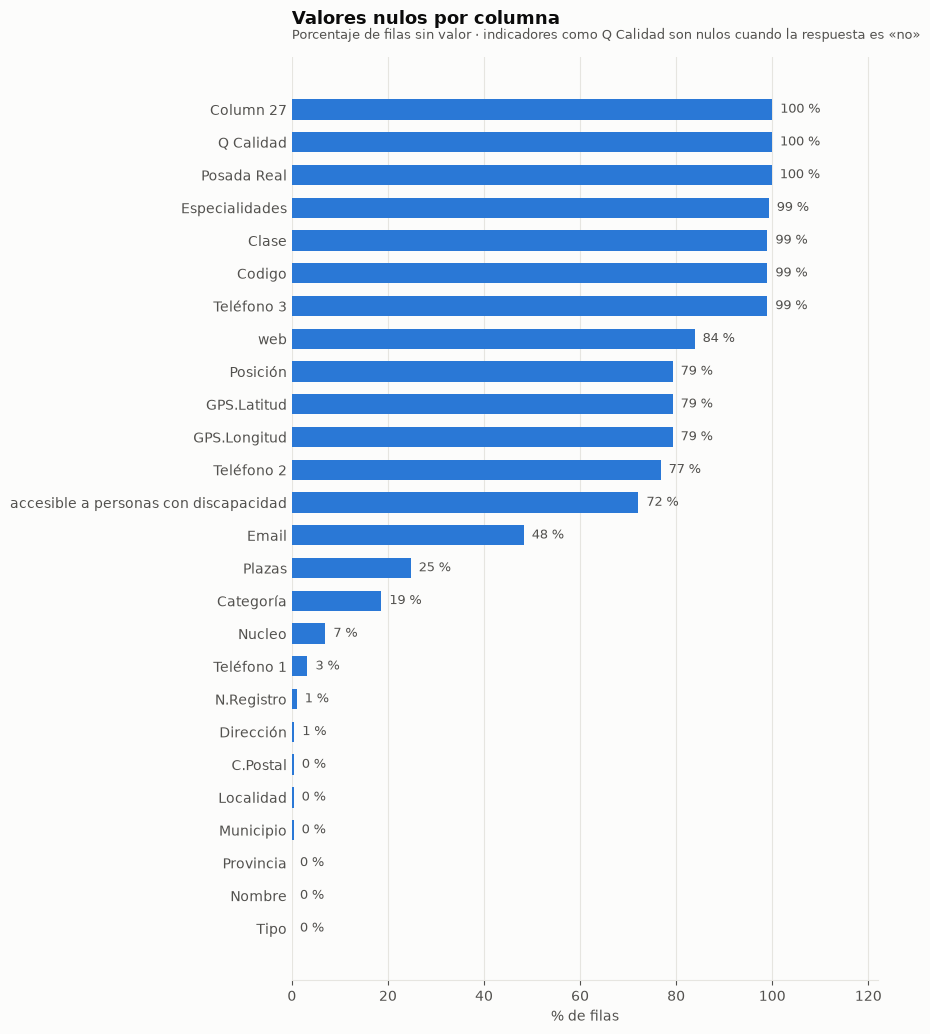

In [29]:
null_pct = hoteles.isna().mean().mul(100)
barh(null_pct[null_pct > 0], "Valores nulos por columna",
     "Porcentaje de filas sin valor · indicadores como Q Calidad son nulos cuando la respuesta es «no»",
     xlabel="% de filas", share=False, suffix=" %")

> Las columnas se dividen en dos bloques: la identificación y la ubicación (nombre, tipo, municipio, teléfono) están casi completas, mientras que los datos de contacto, el GPS y los campos especializados están vacíos en su mayoría.

### Hallazgos principales


- **35.930 establecimientos de 14 tipos**: dominan los bares (40 %) y los restaurantes (17 %); el alojamiento son 12.688 registros con unas **205.000 plazas**.
- `Plazas` son **camas en los alojamientos y asientos en los restaurantes**: nunca se debe sumar entre todos los tipos.
- **El GPS falta en el 79 % de las filas y contiene valores imposibles**: hay que filtrar por los límites de la región o geocodificar por municipio.
- `Q Calidad`, `Posada Real` y la accesibilidad son **indicadores de sí/no guardados como `Si`/nulo**, no columnas vacías.
- 6 registros están fuera de Castilla y León y 312 parecen posibles duplicados.
- Hay que renombrar todas las columnas.

<a id="monumentos"></a>
## 7. Monumentos

Catálogo del patrimonio de la región: una fila por monumento con tipo, clasificación, periodo histórico, una descripción en HTML y coordenadas. Es el **dataset más limpio** y la principal fuente de atractivos.

### Número de filas y columnas

In [30]:
monumentos.shape

(1378, 18)

> **1.378 filas × 18 columnas**: una fila por monumento. Son muchas columnas para su tamaño, porque la ubicación está guardada hasta tres veces (ver más abajo).

### Tipos de columnas

In [31]:
monumentos.info()

<class 'pandas.DataFrame'>
RangeIndex: 1378 entries, 0 to 1377
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   identificador                     1378 non-null   int64  
 1   nombre                            1378 non-null   str    
 2   tipoMonumento                     1378 non-null   str    
 3   identificadorBienInteresCultural  1112 non-null   str    
 4   calle                             886 non-null    str    
 5   clasificacion                     1185 non-null   str    
 6   tipoConstruccion                  1260 non-null   str    
 7   codigoPostal                      1274 non-null   str    
 8   Descripcion                       1368 non-null   str    
 9   periodoHistorico                  1260 non-null   str    
 10  coordenadas_latitud               1378 non-null   float64
 11  coordenadas_longitud              1378 non-null   float64
 12  poblacion_provinc

> 15 columnas de texto, 2 decimales (coordenadas) y 1 entera (`identificador`); 2,3 MB, la mayor parte por las descripciones en HTML. Todas las columnas de ubicación están completas.

### Primeros registros

In [32]:
monumentos.head()

,identificador,nombre,tipoMonumento,identificadorBienInteresCultural,calle,clasificacion,tipoConstruccion,codigoPostal,Descripcion,periodoHistorico,coordenadas_latitud,coordenadas_longitud,poblacion_provincia,poblacion_municipio,poblacion_localidad,pto_geolocalizado,poblacion,coordenadas
0,23778,Catedral de Ávila,Catedrales,264,Pza. de la Catedral s/n,Arquitectura Religiosa,Catedral,5001,"<p align=""justify"">Es una catedral-castillo, en la que l...",Edad Media,"40,66","-4,70",Ávila,Ávila,Ávila,"40.655814, -4.697039","{""provincia"": ""Ávila"", ""municipio"": ""Ávila"", ""localidad""...","{""latitud"": ""40.655814"", ""longitud"": ""-4.697039""}"
1,23779,Catedral de Burgos,Catedrales,1715,Plaza de Santa María s/n,Arquitectura Religiosa,Catedral,9003,"<p align=""justify"">Es uno de los conjuntos arquitect&oac...",Edad Media,"42,34","-3,70",Burgos,Burgos,Burgos,"42.34082, -3.704384","{""provincia"": ""Burgos"", ""municipio"": ""Burgos"", ""localida...","{""latitud"": ""42.340820"", ""longitud"": ""-3.704384""}"
2,23780,Catedral de Astorga,Catedrales,4282,"Pza. de la Catedral, s/n",Arquitectura Religiosa,Catedral,24700,"<p align=""justify"">Es uno de los edificios m&aacute;s re...",Edad Moderna,"42,46","-6,06",León,Astorga,Astorga,"42.457966, -6.056899","{""provincia"": ""León"", ""municipio"": ""Astorga"", ""localidad...","{""latitud"": ""42.457966"", ""longitud"": ""-6.056899""}"
3,23781,Catedral de León,Catedrales,4858,Plaza de la Regla S/N,Arquitectura Religiosa,Catedral,NaN,"<p align=""justify"">Es la Catedral m&aacute;s colorista d...",Edad Media,"42,60","-5,57",León,León,León,"42.599591, -5.566527","{""provincia"": ""León"", ""municipio"": ""León"", ""localidad"": ...","{""latitud"": ""42.599591"", ""longitud"": ""-5.566527""}"
4,23782,Catedral de Palencia,Catedrales,7583,"Plaza de la Inmaculada, s/n",Arquitectura Religiosa,Catedral,34001,"<p align=""justify"">Este edificio, caracterizado por comp...","Edad Moderna,Edad Media","42,01","-4,54",Palencia,Palencia,Palencia,"42.01128, -4.53674","{""provincia"": ""Palencia"", ""municipio"": ""Palencia"", ""loca...","{""latitud"": ""42.01128"", ""longitud"": ""-4.53674""}"


> - `Descripcion` es **HTML sin procesar** (`<p align="justify">`, `&iacute;`).
> - La ubicación aparece tres veces: en columnas separadas (`coordenadas_latitud`, `poblacion_municipio`…), como texto `"lat, lon"` (`pto_geolocalizado`) y como cadenas JSON (`coordenadas`, `poblacion`). Basta con conservar las columnas separadas.
> - `codigoPostal` perdió el cero inicial en el origen (`5001` para Ávila): hay que completarlo a 5 dígitos.

### Estadísticas

In [33]:
monumentos.describe()

,identificador,coordenadas_latitud,coordenadas_longitud
count,"1.378,00","1.378,00","1.378,00"
mean,"32.723,59","41,75","-4,53"
std,"30.716,52","0,72","1,12"
min,"23.778,00","40,15","-6,93"
25%,"25.330,25","41,16","-5,40"
50%,"25.674,50","41,71","-4,60"
75%,"26.020,75","42,34","-3,71"
max,"200.849,00","43,16","-1,86"


> `identificador` va de 23.778 a 200.849: es un identificador, no una cantidad, así que su media no tiene sentido. **La latitud (40,15–43,16) y la longitud (−6,93 a −1,86) caen siempre dentro de la región**: a diferencia del registro de turismo, estas coordenadas se pueden usar directamente.

### Valores nulos

In [34]:
monumentos.isnull().sum()

identificador                         0
nombre                                0
tipoMonumento                         0
identificadorBienInteresCultural    266
calle                               492
clasificacion                       193
tipoConstruccion                    118
codigoPostal                        104
Descripcion                          10
periodoHistorico                    118
coordenadas_latitud                   0
coordenadas_longitud                  0
poblacion_provincia                   1
poblacion_municipio                   1
poblacion_localidad                   1
pto_geolocalizado                     0
poblacion                             1
coordenadas                           0
dtype: int64

La misma información como perfil, ordenada por porcentaje de nulos:

In [35]:
style_profile(monumentos)

,tipo,no_nulos,nulos,pct_nulos,distintos
calle,str,886,492,"35,7 %",777
identificadorBienInteresCultural,str,1.112,266,"19,3 %",1.107
clasificacion,str,1.185,193,"14,0 %",10
tipoConstruccion,str,1.260,118,"8,6 %",49
periodoHistorico,str,1.260,118,"8,6 %",40
codigoPostal,str,1.274,104,"7,5 %",629
Descripcion,str,1.368,10,"0,7 %",1.364
poblacion_provincia,str,1.377,1,"0,1 %",9
poblacion,str,1.377,1,"0,1 %",754
poblacion_municipio,str,1.377,1,"0,1 %",590


> - `calle` (36 %): muchos monumentos (castillos, yacimientos) no tienen dirección postal.
> - `identificadorBienInteresCultural` (19 %): un nulo probablemente significa que el monumento no es *Bien de Interés Cultural*.
> - `clasificacion` (14 %), `periodoHistorico` y `tipoConstruccion` (9 %) y `codigoPostal` (8 %) son huecos reales.
> - Nombre, tipo y ubicación: 0 %.

### Valores duplicados

In [36]:
monumentos.duplicated().sum()

np.int64(0)

In [37]:
monumentos["identificador"].duplicated().sum()

np.int64(4)

> No hay filas completamente duplicadas, pero **4 valores de `identificador` aparecen dos veces**: Las Huelgas (Burgos), Santa Clara (Tordesillas), La Granja y Riofrío (San Ildefonso) están dos veces con algún campo distinto. Hay que quedarse con una fila por identificador. Los nombres repetidos (228) son normales: muchos pueblos tienen una *Iglesia de San Juan*.

### Nombre de las columnas

In [38]:
monumentos.columns

Index(['identificador', 'nombre', 'tipoMonumento',
       'identificadorBienInteresCultural', 'calle', 'clasificacion',
       'tipoConstruccion', 'codigoPostal', 'Descripcion', 'periodoHistorico',
       'coordenadas_latitud', 'coordenadas_longitud', 'poblacion_provincia',
       'poblacion_municipio', 'poblacion_localidad', 'pto_geolocalizado',
       'poblacion', 'coordenadas'],
      dtype='str')

> Los nombres mezclan camelCase (`tipoMonumento`), guiones bajos (`poblacion_provincia`) y una mayúscula inicial (`Descripcion`). Se entienden, pero no son coherentes con los otros datasets.

### Distribuciones

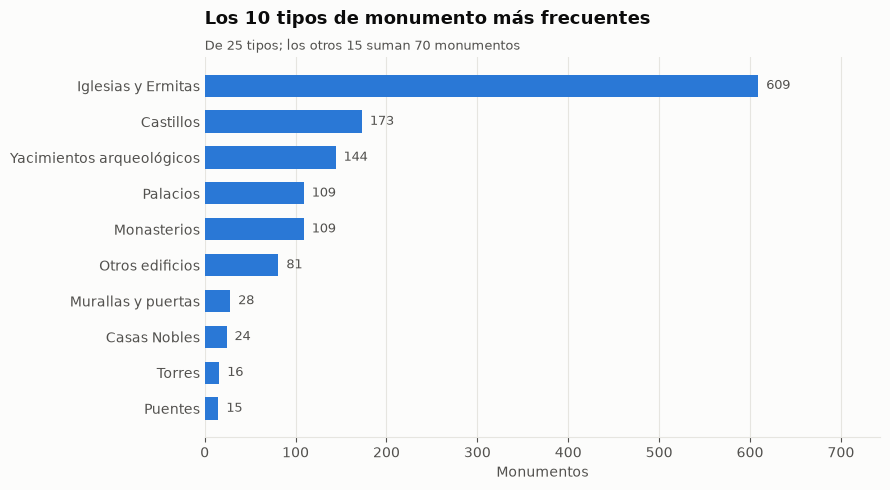

In [39]:
monument_types = monumentos["tipoMonumento"].value_counts()
barh(monument_types.head(10), "Los 10 tipos de monumento más frecuentes",
     f"De {len(monument_types)} tipos; los otros {len(monument_types) - 10} suman "
     f"{monument_types.iloc[10:].sum()} monumentos", xlabel="Monumentos", share=False)

> **Domina el patrimonio religioso**: iglesias y ermitas son el 44 % del catálogo (609), cinco veces más que los castillos (173). Los yacimientos arqueológicos (144) son el tercer grupo, interesante para un producto de rutas culturales.

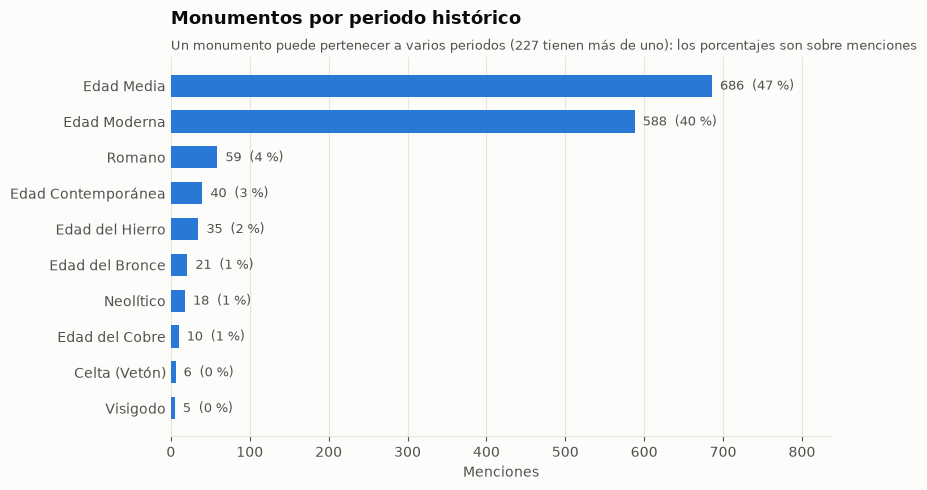

In [40]:
periods = monumentos["periodoHistorico"].dropna().str.split(",").explode().str.strip()
barh(periods.value_counts().head(10), "Monumentos por periodo histórico",
     f"Un monumento puede pertenecer a varios periodos ({monumentos['periodoHistorico'].str.contains(',', na=False).sum()} "
     "tienen más de uno): los porcentajes son sobre menciones", xlabel="Menciones")

> Tras separar las celdas con varios valores, **la Edad Media (686) y la Edad Moderna (588) suman el 85 % de las menciones**. El patrimonio romano y prehistórico es minoritario (59 menciones romanas), pero está bien localizado.

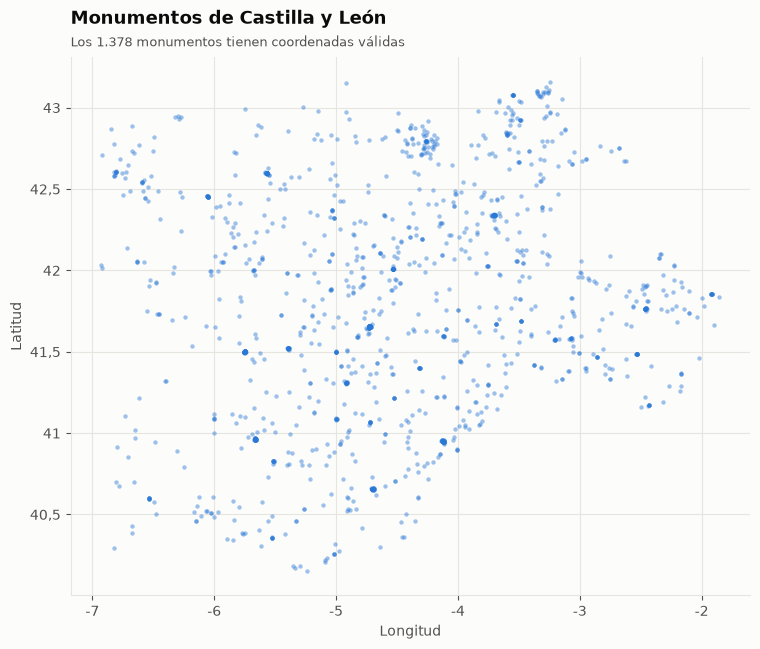

In [41]:
scatter_map(monumentos["coordenadas_longitud"], monumentos["coordenadas_latitud"],
            "Monumentos de Castilla y León", "Los 1.378 monumentos tienen coordenadas válidas", sizes=10)

> Los monumentos cubren todo el territorio, con pequeñas concentraciones (puntos más oscuros) en las capitales de provincia y en las villas históricas. Con las coordenadas completas, este dataset puede alimentar directamente mapas y recomendaciones de rutas.

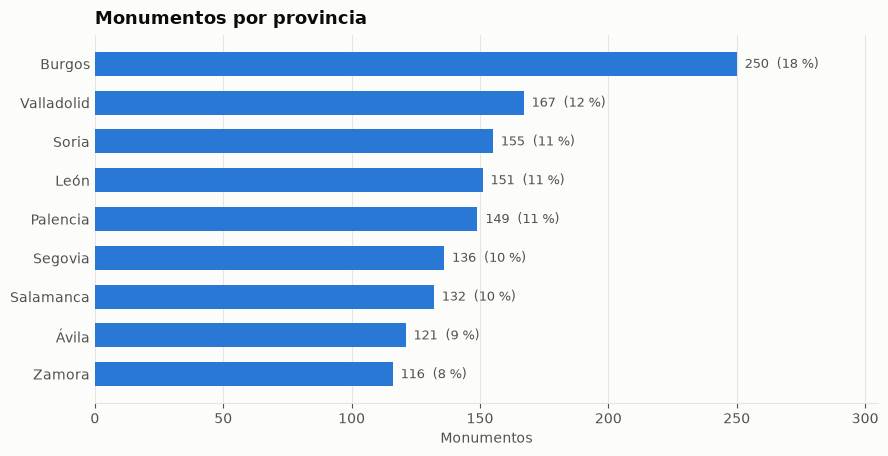

In [42]:
barh(monumentos["poblacion_provincia"].value_counts(), "Monumentos por provincia", xlabel="Monumentos")

> **Burgos encabeza la lista con 250 monumentos (18 %)**, muy por delante de Valladolid (167). Zamora y Ávila cierran la clasificación con unos 120 cada una.

### Hallazgos principales


- **1.378 monumentos con la ubicación completa y válida al 100 %**: listos para mapas.
- Iglesias y ermitas son el 44 %; la Edad Media y la Edad Moderna suman el 85 % de las menciones de periodo.
- `Descripcion` es HTML: hay que quitar las etiquetas y decodificar las entidades antes de usarla como texto.
- `periodoHistorico` tiene varios valores por celda: hay que separarlos antes de contar.
- **4 monumentos están duplicados** con el mismo `identificador`.
- La ubicación está guardada tres veces: sobran `pto_geolocalizado`, `poblacion` y `coordenadas`.

<a id="oficinas"></a>
## 8. Oficinas de turismo

Oficinas de información turística con provincia, localidad, tipo y ámbito administrativo. Es el dataset más pequeño y **no tiene columnas numéricas ni coordenadas**.

### Número de filas y columnas

In [43]:
oficinas.shape

(263, 6)

> **263 filas × 6 columnas**: una fila por oficina. Una tabla muy pequeña, útil como indicador de servicios turísticos más que para análisis pesados.

### Tipos de columnas

In [44]:
oficinas.info()

<class 'pandas.DataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Provincia                     263 non-null    str  
 1   Localidad                     263 non-null    str  
 2   Tipo                          245 non-null    str  
 3   Nombre del recurso turístico  263 non-null    str  
 4   Establecimiento               261 non-null    str  
 5   Ámbito                        258 non-null    str  
dtypes: str(6)
memory usage: 12.5 KB


> Las 6 columnas son de texto; 0,1 MB. No hay datos numéricos ni coordenadas, así que las oficinas solo se pueden ubicar a través de `Localidad`.

### Primeros registros

In [45]:
oficinas.head()

,Provincia,Localidad,Tipo,Nombre del recurso turístico,Establecimiento,Ámbito
0,Ávila,La Adrada,Información,Oficina de Turismo de La Adrada,Oficina de Turismo,Municipal
1,Ávila,La Adrada,NaN,Punto de información turística Museo Histórico Castillo ...,Oficina de Turismo,NaN
2,Ávila,El Arenal,Información,Oficina de Turismo de El Arenal,Oficina de Turismo,Municipal
3,Ávila,Arenas de San Pedro,Información,Oficina de Turismo de Arenas de San Pedro,Oficina de Turismo,Municipal
4,Ávila,Arévalo,Información,Oficina de Turismo de Arévalo,Oficina de Turismo,Municipal


> Cada fila es una oficina con su nombre (`Oficina de Turismo de La Adrada`), su localidad y su ámbito. Los nombres son únicos y descriptivos.

### Estadísticas

In [46]:
oficinas.describe()

,Provincia,Localidad,Tipo,Nombre del recurso turístico,Establecimiento,Ámbito
count,263,263,245,263,261,258
unique,10,245,1,263,3,3
top,Valladolid,Valladolid,Información,Oficina de Turismo de La Adrada,Oficina de Turismo,Municipal
freq,59,4,245,1,256,248


> Como todas las columnas son de texto, `describe()` muestra el recuento, los valores distintos y el valor más frecuente en lugar de estadísticas:
> - 263 nombres distintos (uno por oficina) en **245 localidades**: algunas tienen varias oficinas (Valladolid capital tiene 4).
> - `Provincia` tiene **10 valores**, uno más que la región: hay una oficina en Madrid.
> - `Tipo` tiene un único valor (`Información`), así que no aporta información.

### Valores nulos

In [47]:
oficinas.isnull().sum()

Provincia                        0
Localidad                        0
Tipo                            18
Nombre del recurso turístico     0
Establecimiento                  2
Ámbito                           5
dtype: int64

La misma información como perfil, ordenada por porcentaje de nulos:

In [48]:
style_profile(oficinas)

,tipo,no_nulos,nulos,pct_nulos,distintos
Tipo,str,245,18,"6,8 %",1
Ámbito,str,258,5,"1,9 %",3
Establecimiento,str,261,2,"0,8 %",3
Provincia,str,263,0,"0,0 %",10
Localidad,str,263,0,"0,0 %",245
Nombre del recurso turístico,str,263,0,"0,0 %",263


> Muy pocos huecos: `Tipo` 18, `Ámbito` 5 y `Establecimiento` 2. Como `Tipo` solo tiene un valor, sus nulos no importan.

### Valores duplicados

In [49]:
oficinas.duplicated().sum()

np.int64(0)

> No hay filas duplicadas.

### Nombre de las columnas

In [50]:
oficinas.columns

Index(['Provincia', 'Localidad', 'Tipo', 'Nombre del recurso turístico',
       'Establecimiento', 'Ámbito'],
      dtype='str')

> Nombres con espacios y tildes (`Nombre del recurso turístico`, `Ámbito`); hay que renombrarlos igual que en los otros datasets.

### Distribuciones

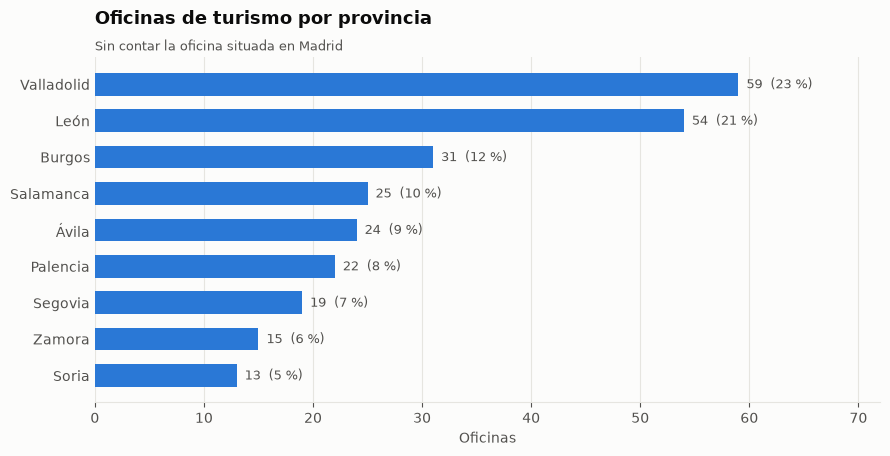

In [51]:
barh(oficinas.loc[oficinas["Provincia"].isin(CYL_PROVINCES), "Provincia"].value_counts(), "Oficinas de turismo por provincia", "Sin contar la oficina situada en Madrid", xlabel="Oficinas")

> **Valladolid (59) y León (54) reúnen casi la mitad de las oficinas**, mientras que Soria solo tiene 13.

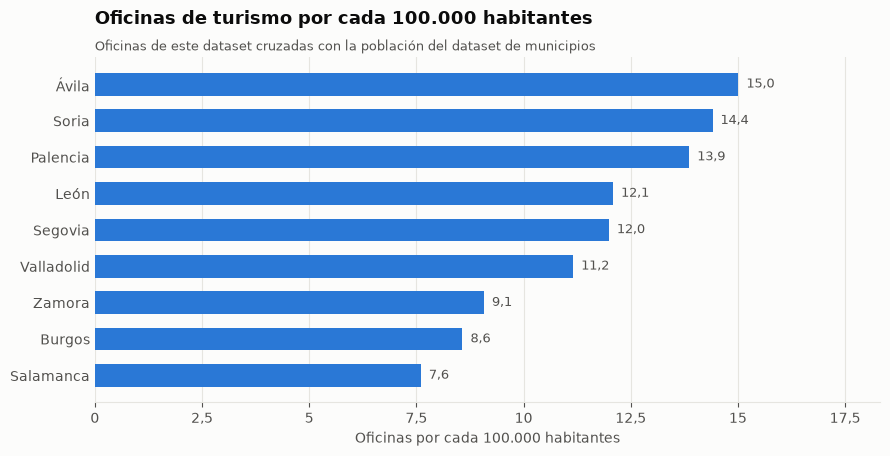

In [52]:
offices = oficinas.loc[oficinas["Provincia"].isin(CYL_PROVINCES), "Provincia"].value_counts()
population = municipios.groupby("Provincia")["Población"].sum()
population.index = population.index.str.title()
per_100k = (offices / population * 100_000).dropna()
barh(per_100k, "Oficinas de turismo por cada 100.000 habitantes",
     "Oficinas de este dataset cruzadas con la población del dataset de municipios",
     xlabel="Oficinas por cada 100.000 habitantes", share=False, dec=1)

> En relación con la población, la clasificación cambia: **Ávila y Soria ofrecen más oficinas por habitante** que Valladolid, que lidera en números absolutos. Este cruce sencillo ya muestra cómo combinar datasets produce indicadores que una sola tabla no puede dar.

### Hallazgos principales


- **263 oficinas**, casi todas municipales (248); Valladolid y León concentran la mayoría.
- En relación con la población, **Ávila y Soria están mejor atendidas**.
- `Tipo` tiene un único valor: se puede eliminar.
- 1 oficina está en Madrid.
- No hay coordenadas y algunos valores de `Localidad` añaden el municipio entre paréntesis (`Orbaneja del Castillo (Valle de Sedano)`): solo un 92 % coincide directamente con un nombre de municipio.

<a id="summary"></a>
## 9. Conclusiones

### ¿Cuáles tienen más valores nulos?

In [53]:
(
    overview[["filas", "pct_celdas_nulas"]]
    .sort_values("pct_celdas_nulas", ascending=False)
    .style
    .bar(subset=["pct_celdas_nulas"], color=ACCENT_LIGHT, vmin=0, vmax=100)
    .format(thousands=".")
    .format("{:.1f} %", subset=["pct_celdas_nulas"], decimal=",")
)

,filas,pct_celdas_nulas
dataset,,
hoteles,35.930,"47,1 %"
municipios,2.248,"14,5 %"
monumentos,1.378,"5,3 %"
oficinas,263,"1,6 %"


- **`hoteles` es con diferencia el más incompleto (47,1 % de celdas nulas)**. Mezcla 14 tipos de establecimiento en una sola tabla, así que cada tipo deja vacíos los campos que no le corresponden. Parte de esos nulos no son datos perdidos, sino un *«no»* en columnas de sí/no (`Q Calidad`, `Posada Real`, accesibilidad).
- **`municipios` va después (14,5 %)**, pero casi todo es estructural: `Comarca` solo se aplica a El Bierzo y `Entidades_Locales_Menores` solo a los municipios que las tienen.
- **`monumentos` (5,3 %) y `oficinas` (1,6 %) están casi completos.**

### ¿Qué problemas aparecen?

| # | Problema | Dataset | Acción |
|---|---|---|---|
| 1 | Nombres escritos de forma distinta (`ÁVILA` frente a `Ávila`, `EL BARRACO` frente a `Barraco (El)`) | todos | Normalizar mayúsculas, tildes y artículos antes de cruzar |
| 2 | Registros fuera de Castilla y León (Somiedo, Madrid…) | hoteles, oficinas | Filtrar por las 9 provincias |
| 3 | GPS ausente en el 79 % y con valores imposibles (latitud de −5 a 53,8) | hoteles | Quedarse solo con los puntos dentro de la región; geocodificar el resto por municipio |
| 4 | `Plazas` significa camas o asientos según el tipo | hoteles | Analizar la capacidad solo dentro de los tipos de alojamiento |
| 5 | Indicadores de sí/no guardados como `Si`/nulo | hoteles | Convertir `Q Calidad`, `Posada Real` y accesibilidad a booleanos |
| 6 | Posibles duplicados: 312 establecimientos y 4 identificadores de monumento | hoteles, monumentos | Revisar y dejar una fila por establecimiento / identificador |
| 7 | HTML sin procesar en las descripciones | monumentos | Quitar etiquetas y decodificar las entidades HTML |
| 8 | Periodo histórico con varios valores | monumentos | Separar y expandir |
| 9 | Ubicación guardada tres veces | monumentos | Eliminar `pto_geolocalizado`, `poblacion` y `coordenadas` |
| 10 | Columnas vacías o con un único valor | hoteles, oficinas | Eliminar `Column 27` y `Tipo` |
| 11 | Nombres de columna incoherentes (espacios, puntos, tildes) | todos | Renombrar a minúsculas sin tildes con guiones bajos |

### ¿Qué datos serán útiles para SmartTour?

SmartTour quiere analizar datos turísticos para mejorar la toma de decisiones. Los datos más valiosos para ello son:

- **Oferta y capacidad de alojamiento** (`hoteles`): 12.688 registros de alojamiento con `Plazas` casi completo, unas 205.000 plazas. Permite medir la capacidad por provincia y municipio.
- **Atractivos patrimoniales** (`monumentos`): tipo, periodo histórico y **coordenadas completas y válidas**, listos para mapas y rutas.
- **Territorio y población** (`municipios`): `Cod_INE`, población y coordenadas. Es la **clave común** para cruzar los demás datasets y calcular ratios como plazas u oficinas por habitante, como ya muestra la sección de oficinas.
- **Red de información turística** (`oficinas`): cobertura de servicios turísticos por provincia y localidad.
- **Restaurantes, bares y turismo activo** (`hoteles`): oferta complementaria para describir cada destino.

### ¿Qué información falta?

- **Datos de demanda**: número de visitantes, pernoctaciones, ocupación u origen de los turistas. Sin ellos se puede describir la oferta, pero no medir el turismo.
- **Dimensión temporal**: ningún dataset tiene fechas, así que no se pueden estudiar tendencias ni estacionalidad.
- **Precios y valoraciones**: no hay precios ni opiniones; la única señal de calidad es el indicador `Q Calidad`, que tienen 17 establecimientos.
- **Información práctica de los monumentos**: horarios, precio de la entrada y número de visitantes.
- **Coordenadas**: el 79 % de los establecimientos y todas las oficinas carecen de coordenadas válidas.
- **Una clave común**: los datasets solo comparten los **nombres** de municipio y provincia, no el código INE, así que los cruces necesitarán normalizar el texto (las coincidencias directas son solo del 92–96 %).

**Siguiente paso:** un cuaderno de limpieza (`02_...`) que aplique estas acciones y exporte los datos limpios (Parquet) para la fase de integración.